# VAE Assignment 3: Comparative Study of the Standard VAE and the β-VAE

| Task | What we do |
|---|---|
| 1 | Implement a standard VAE (β = 1) and β-VAEs on the **same dataset** (MNIST) |
| 2 | Study the effect of β on reconstruction quality and latent-space regularisation |
| 3 | Compare reconstruction loss, KL, total loss and generated samples for each β |
| 4 | Visualise the latent representations of the models |
| 5 | Decide which model is more **disentangled** and justify it (traversals + metrics) |
| 6 | Real-world applications of VAEs and their limitations compared with GANs |

> ⚡ Every model trains for only **5 epochs**. That is short, but enough to show clear trends between the β values.

## Background: β-VAE

The β-VAE (Higgins et al., ICLR 2017) changes **one number** in the VAE objective:

$$\mathcal{L}_\beta = \mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)] \;-\; \beta\, D_{KL}\big(q_\phi(z\mid x)\,\|\,\mathcal{N}(0,I)\big)$$

* **β = 1** gives the standard VAE (the true ELBO).
* **β > 1** puts a stronger penalty on the KL term. This gives a stronger **information bottleneck**, and the posterior is pushed towards the **factorised** isotropic prior. Each latent dimension is encouraged to be independent and to encode one **separate factor of variation** (e.g. thickness, slant, width). This is called **disentanglement**.
* **The price:** less information passes through $z$, so **reconstructions get blurrier**.

## Setup

In [1]:
import os, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")
sns.set_style("white")

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)
os.makedirs("data", exist_ok=True)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Device: mps


In [2]:
def load_images(name="MNIST"):
    """Download a torchvision dataset and return tensors (N,1,28,28) in [0,1] already on the device."""
    cls = getattr(torchvision.datasets, name)
    tr, te = cls("data", train=True, download=True), cls("data", train=False, download=True)
    to_t = lambda ds: ds.data.float().div(255.).unsqueeze(1).to(device)
    return to_t(tr), tr.targets.clone(), to_t(te), te.targets.clone(), tr.classes

def batches(X, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        yield X[idx[i:i + bs]]

Xtr, ytr, Xte, yte, classes = load_images("MNIST")
print("Train:", tuple(Xtr.shape), " Test:", tuple(Xte.shape))

Train: (60000, 1, 28, 28)  Test: (10000, 1, 28, 28)


## Task 1: Implementation (one architecture, different β)
All models share the same MLP architecture (784 → 400 → **10-D latent** → 400 → 784) and the same seed. The **only** difference is β in the loss.

In [3]:
class VAE(nn.Module):
    """Fully-connected VAE:  784 -> 400 -> (mu, logvar) [latent_dim]  ->  400 -> 784"""
    def __init__(self, latent_dim=10, hidden=400):
        super().__init__()
        self.latent_dim = latent_dim
        # ----- Encoder  q_phi(z|x) -----
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, hidden), nn.ReLU())
        self.fc_mu = nn.Linear(hidden, latent_dim)
        self.fc_logvar = nn.Linear(hidden, latent_dim)
        # ----- Decoder  p_theta(x|z) -----
        self.dec = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)          # sigma = exp(log(sigma^2)/2)
        eps = torch.randn_like(std)            # eps ~ N(0, I)
        return mu + std * eps                  # z = mu + sigma * eps

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    """Returns (total, reconstruction, KL), all SUMMED over the batch.
       recon = BCE(x_hat, x)                      ~  -E_q[log p(x|z)]
       KL    = -1/2 * sum(1 + log s^2 - mu^2 - s^2)  =  KL(q(z|x) || N(0, I))"""
    recon = F.binary_cross_entropy(x_hat.reshape(len(x), -1), x.reshape(len(x), -1), reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + beta * kl, recon, kl

def train_vae(model, Xtr, Xte, epochs=5, beta=1.0, lr=1e-3, bs=128, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_total", "train_recon", "train_kl", "test_total", "test_recon", "test_kl"]}
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); s = np.zeros(3)
        for xb in batches(Xtr, bs):
            x_hat, mu, logvar = model(xb)
            loss, rec, kl = vae_loss(x_hat, xb, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            s += [loss.item(), rec.item(), kl.item()]
        s /= len(Xtr)                                   # per-image averages
        te = evaluate(model, Xte, beta)
        for k, v in zip(hist, list(s) + list(te)): hist[k].append(v)
        if verbose:
            print(f"epoch {ep}/{epochs} | train total={s[0]:.2f} recon={s[1]:.2f} KL={s[2]:.2f} "
                  f"| test total={te[0]:.2f} recon={te[1]:.2f} KL={te[2]:.2f} ({time.time()-t0:.1f}s)")
    return hist

@torch.no_grad()
def evaluate(model, X, beta=1.0, bs=1000):
    model.eval(); s = np.zeros(3)
    for xb in batches(X, bs, shuffle=False):
        x_hat, mu, logvar = model(xb)
        s += [t.item() for t in vae_loss(x_hat, xb, mu, logvar, beta)]
    return s / len(X)

@torch.no_grad()
def encode_mu(model, X, bs=1000):
    model.eval()
    return torch.cat([model.encode(xb)[0] for xb in batches(X, bs, shuffle=False)]).cpu().numpy()

def show_grid(imgs, nrow, title=None, ax=None, size=1.0):
    imgs = imgs.detach().cpu().reshape(-1, 1, 28, 28)
    grid = torchvision.utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.figure(figsize=(nrow * size, (len(imgs) // nrow) * size)); ax = plt.gca()
    ax.imshow(grid, cmap="gray"); ax.axis("off")
    if title: ax.set_title(title)

In [4]:
BETAS = [1, 2, 4, 8]          # beta = 1 -> standard VAE
LATENT, EPOCHS = 10, 5
models, hists = {}, {}
for b in BETAS:
    print(f"\n========== beta = {b} {'(standard VAE)' if b == 1 else '(beta-VAE)'} ==========")
    set_seed(42)
    m = VAE(latent_dim=LATENT).to(device)
    hists[b] = train_vae(m, Xtr, Xte, epochs=EPOCHS, beta=b)
    models[b] = m


========== beta = 1 (standard VAE) ==========


epoch 1/5 | train total=162.96 recon=149.38 KL=13.57 | test total=128.66 recon=111.99 KL=16.67 (3.0s)


epoch 2/5 | train total=124.72 recon=107.90 KL=16.83 | test total=120.15 recon=103.07 KL=17.08 (1.8s)


epoch 3/5 | train total=119.49 recon=102.23 KL=17.26 | test total=117.02 recon=99.05 KL=17.96 (1.8s)


epoch 4/5 | train total=116.88 recon=99.34 KL=17.55 | test total=114.94 recon=97.19 KL=17.76 (1.8s)


epoch 5/5 | train total=115.24 recon=97.49 KL=17.76 | test total=113.53 recon=95.80 KL=17.73 (1.8s)

========== beta = 2 (beta-VAE) ==========


... (11 outputs left out)

epoch 2/5 | train total=184.29 recon=156.13 KL=3.52 | test total=181.89 recon=151.81 KL=3.76 (1.8s)


epoch 3/5 | train total=181.51 recon=150.06 KL=3.93 | test total=180.48 recon=147.87 KL=4.08 (1.8s)


epoch 4/5 | train total=180.13 recon=146.88 KL=4.16 | test total=178.85 recon=144.39 KL=4.31 (1.8s)


epoch 5/5 | train total=179.01 recon=144.82 KL=4.27 | test total=178.04 recon=145.47 KL=4.07 (2.0s)


## Tasks 2–3: Compare reconstruction loss, KL, total loss and generated samples
* `Total (β-weighted)` = Recon + β·KL, the objective each model actually minimised
* `-ELBO (β=1)` = Recon + KL, the standard ELBO. This puts all models on the same scale.

,Recon (BCE),KL,Total (β-weighted),-ELBO (β=1),Pixel MSE
β,,,,,
1,95.798,17.735,113.533,113.533,0.018
2,102.911,13.155,129.222,116.067,0.019
4,118.011,8.489,151.967,126.500,0.022
8,145.474,4.071,178.042,149.545,0.032


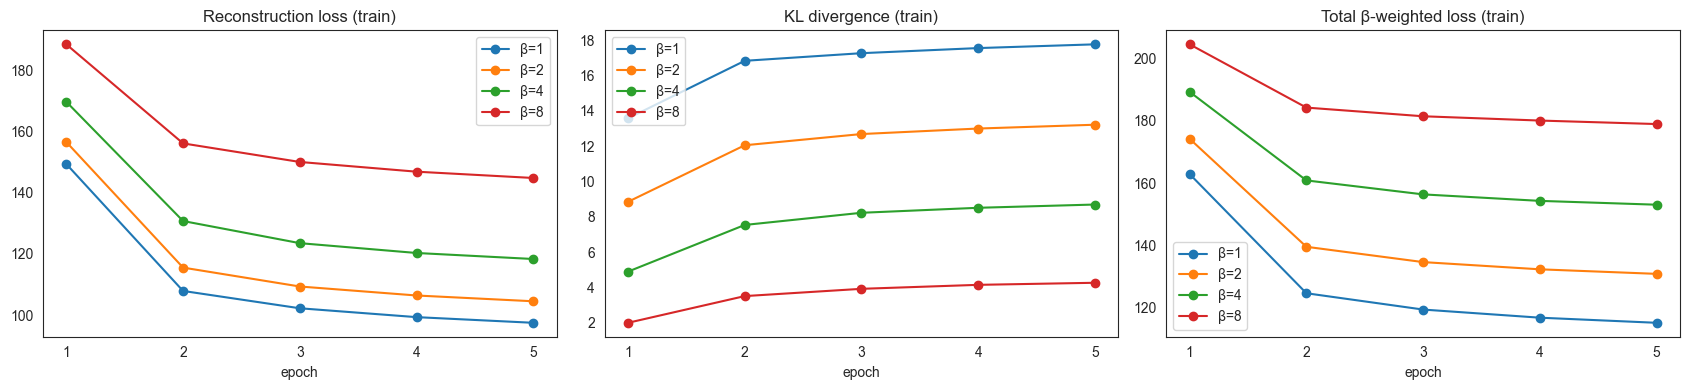

In [5]:
rows = {}
for b in BETAS:
    rec, kl = hists[b]["test_recon"][-1], hists[b]["test_kl"][-1]
    with torch.no_grad():
        mse = F.mse_loss(models[b].decode(models[b].encode(Xte[:2000])[0]), Xte[:2000]).item()
    rows[b] = {"Recon (BCE)": rec, "KL": kl, "Total (β-weighted)": rec + b * kl, "-ELBO (β=1)": rec + kl, "Pixel MSE": mse}
results = pd.DataFrame(rows).T.round(3); results.index.name = "β"
display(results)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ep = range(1, EPOCHS + 1)
for b in BETAS:
    axes[0].plot(ep, hists[b]["train_recon"], "o-", label=f"β={b}")
    axes[1].plot(ep, hists[b]["train_kl"], "o-", label=f"β={b}")
    axes[2].plot(ep, hists[b]["train_total"], "o-", label=f"β={b}")
for ax, t in zip(axes, ["Reconstruction loss (train)", "KL divergence (train)", "Total β-weighted loss (train)"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(); ax.set_xticks(list(ep))
plt.tight_layout(); plt.show()

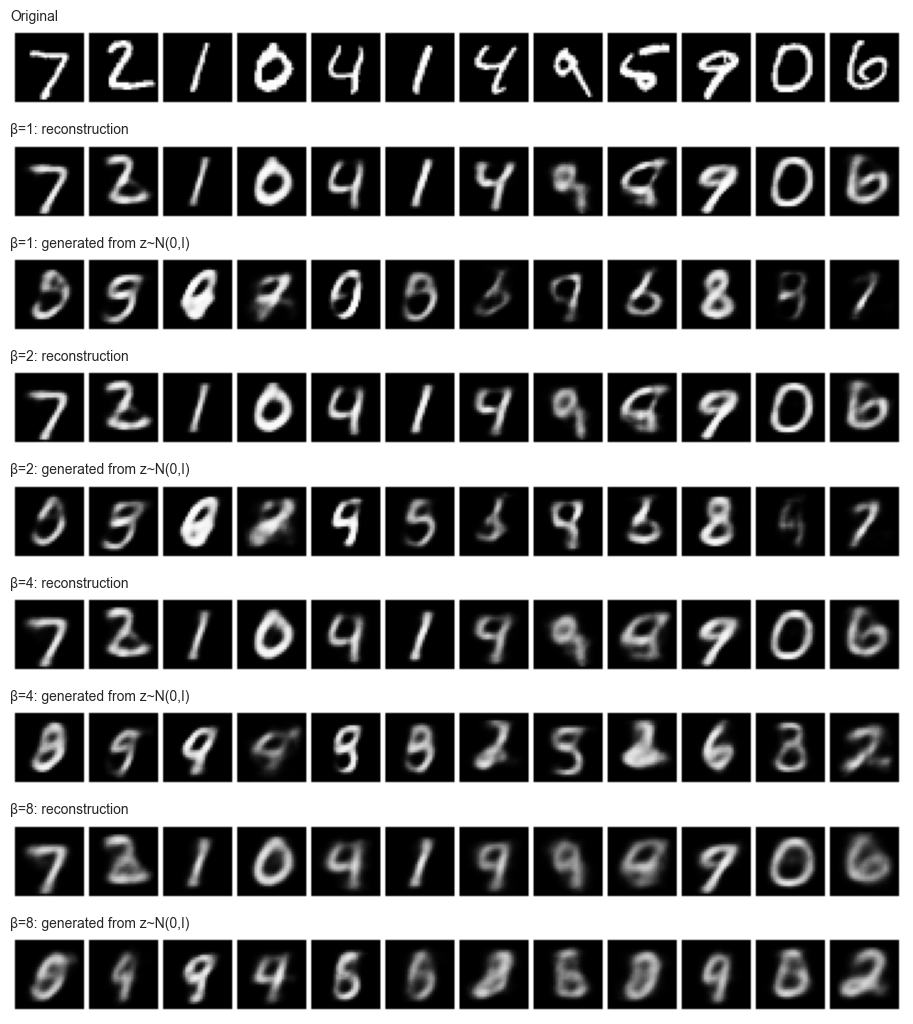

In [6]:
# Reconstructions and random samples for every beta
x = Xte[:12]; set_seed(3); z_prior = torch.randn(12, LATENT, device=device)
fig, axes = plt.subplots(1 + 2 * len(BETAS), 1, figsize=(12, 1.15 * (1 + 2 * len(BETAS))))
show_grid(x, nrow=12, ax=axes[0]); axes[0].set_title("Original", loc="left", fontsize=10)
with torch.no_grad():
    for i, b in enumerate(BETAS):
        models[b].eval()
        show_grid(models[b].decode(models[b].encode(x)[0]), nrow=12, ax=axes[1 + 2 * i])
        axes[1 + 2 * i].set_title(f"β={b}: reconstruction", loc="left", fontsize=10)
        show_grid(models[b].decode(z_prior), nrow=12, ax=axes[2 + 2 * i])
        axes[2 + 2 * i].set_title(f"β={b}: generated from z~N(0,I)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Effect of β (Task 2):**
* **Reconstruction quality falls as β increases.** The test BCE rises from **95.8 (β=1) → 102.9 (β=2) → 118.0 (β=4) → 145.5 (β=8)**, and pixel MSE rises from 0.018 to 0.032. At β = 8 some digits are even reconstructed as a *different*, more prototypical digit.
* **The KL divergence falls as β increases**, from **17.7 → 13.2 → 8.5 → 4.1** nats. The posterior is closer to the prior, so the latent space is more strongly **regularised** and carries fewer bits of information about $x$.
* The **unweighted −ELBO is best for β = 1** (113.5, against 116.1, 126.5 and 149.5), as theory predicts, because β = 1 is the model that optimises exactly this quantity.
* **Generated samples:** with higher β the samples become smoother, rounder and more uniform. The aggregate posterior matches the prior better, so there are fewer "garbage" samples, but they are also blurrier and less detailed.

## Task 4: Visualising the latent representations

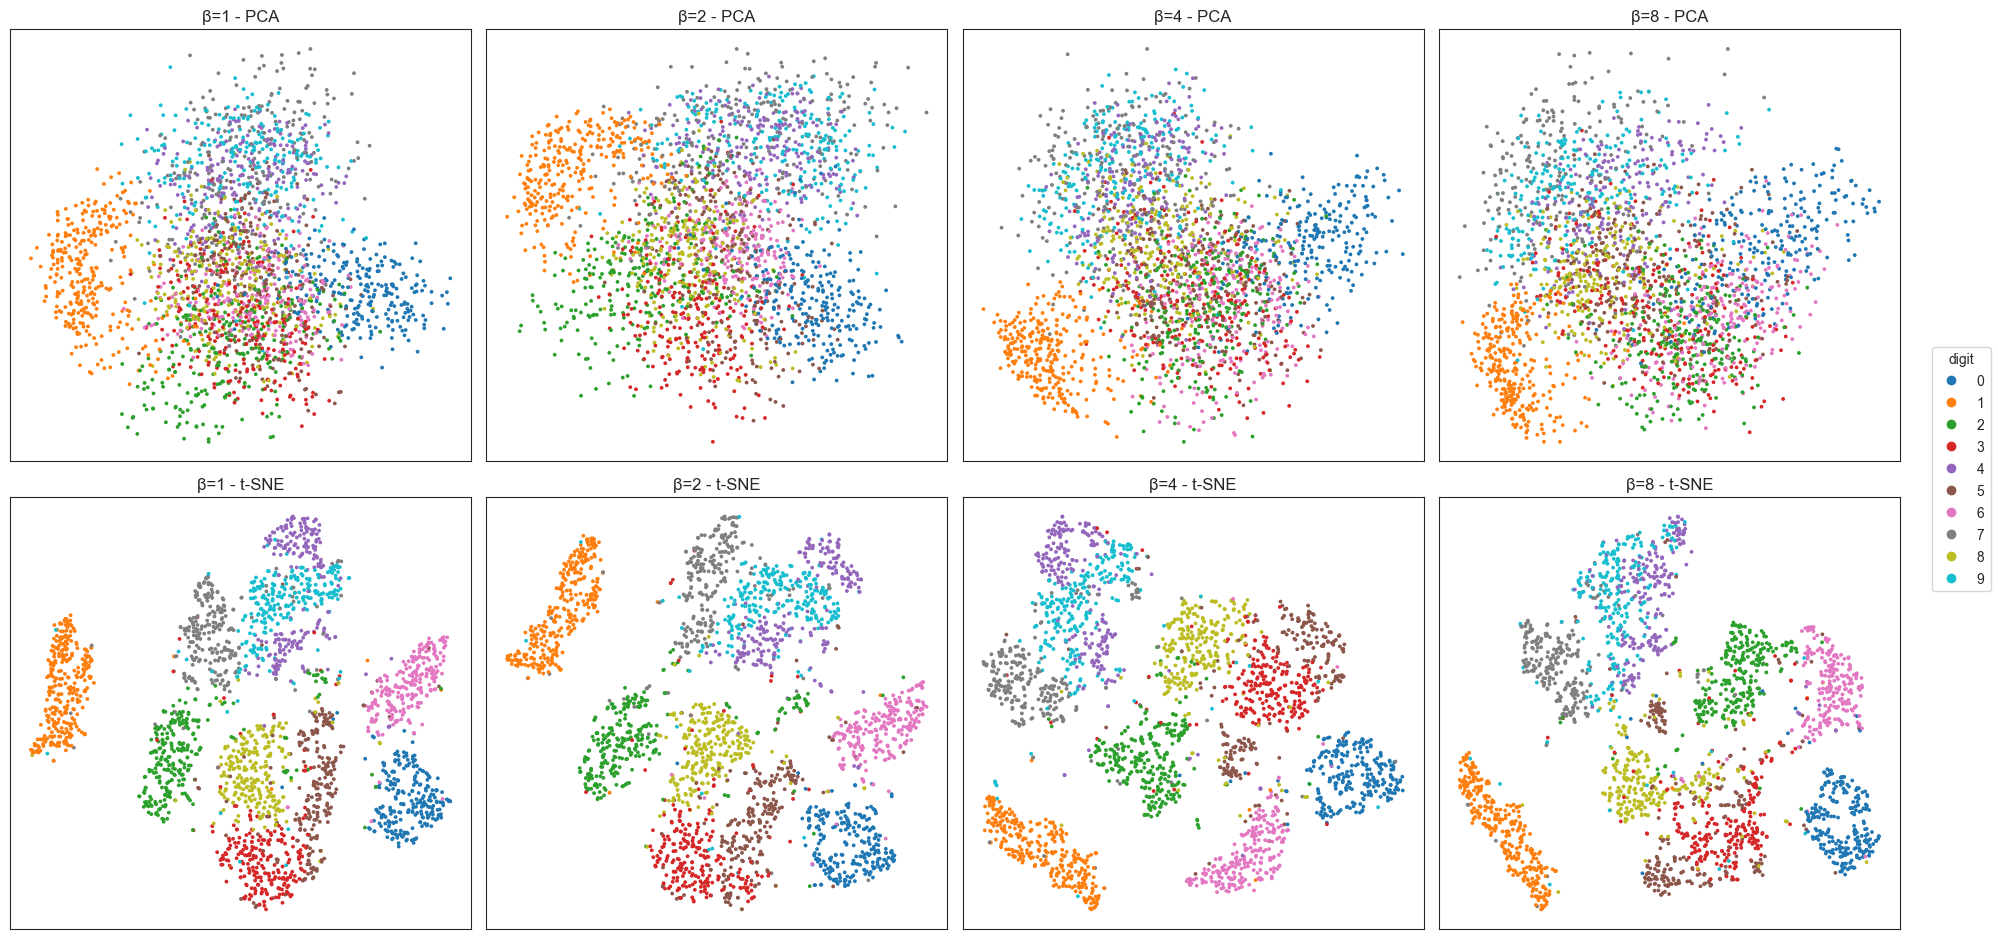

In [7]:
sel = torch.randperm(len(Xte))[:2500]; lab = yte[sel].numpy()
fig, axes = plt.subplots(2, len(BETAS), figsize=(5 * len(BETAS), 9.5))
for j, b in enumerate(BETAS):
    Z = encode_mu(models[b], Xte[sel])
    for i, P in enumerate([PCA(2).fit_transform(Z), TSNE(2, random_state=0, init="pca").fit_transform(Z)]):
        sc = axes[i, j].scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", s=3)
        axes[i, j].set_title(f"β={b} - {'PCA' if i == 0 else 't-SNE'}"); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
fig.legend(*sc.legend_elements(), loc="center right", title="digit")
plt.tight_layout(rect=[0, 0, 0.96, 1]); plt.show()

## Task 5: Which model is more disentangled?

Disentanglement means that **each latent dimension controls one interpretable factor**, and the dimensions are **independent**. We measure it in three ways:

1. **Active units:** a dimension is *active* if its encoder mean varies across the data ($\mathrm{Var}_x[\mu_j] > 0.01$). Fewer, more informative units means a more compact, factorised code.
2. **Per-dimension KL:** how much information each dimension carries.
3. **Statistical independence:** the mean absolute correlation between the latent means of the active dimensions. Lower is more independent. This is a simple proxy for total correlation.
4. **Latent traversals (qualitative):** fix an image's code, change **one** dimension from −3 to +3 and decode. In a disentangled model each row shows **one** clean change (e.g. only slant, or only thickness).

,Active units (of 10),Total KL,Mean |corr| between active dims
β,,,
1,10.0,17.735,0.080
2,10.0,13.155,0.058
4,10.0,8.489,0.043
8,8.0,4.071,0.068


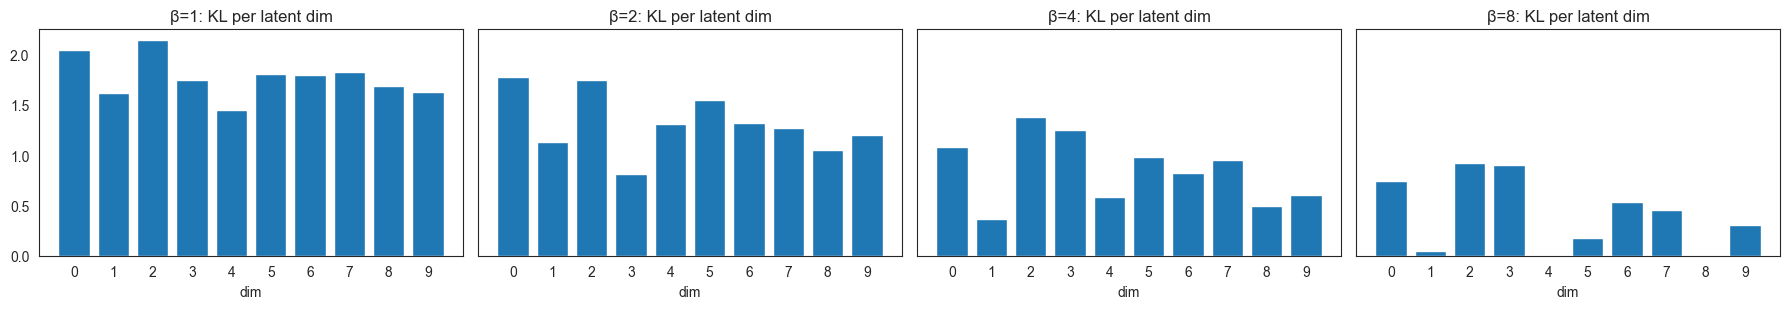

In [8]:
@torch.no_grad()
def latent_stats(m):
    mus, lvs = [], []
    for xb in batches(Xte, 1000, shuffle=False):
        mu, lv = m.encode(xb); mus.append(mu); lvs.append(lv)
    mu, lv = torch.cat(mus), torch.cat(lvs)
    kl_dim = (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).mean(0).cpu().numpy()
    var_mu = mu.var(0).cpu().numpy()
    active = var_mu > 0.01
    mu_np = mu.cpu().numpy()[:, active]
    corr = np.corrcoef(mu_np.T) if active.sum() > 1 else np.ones((1, 1))
    offdiag = np.abs(corr[~np.eye(len(corr), dtype=bool)]).mean() if active.sum() > 1 else 0.0
    return kl_dim, var_mu, active, offdiag

stats = {b: latent_stats(models[b]) for b in BETAS}
dis = pd.DataFrame({b: {"Active units (of 10)": int(s[2].sum()), "Total KL": s[0].sum(),
                        "Mean |corr| between active dims": s[3]} for b, s in stats.items()}).T.round(3)
dis.index.name = "β"; display(dis)

fig, axes = plt.subplots(1, len(BETAS), figsize=(18, 3.2), sharey=True)
for ax, b in zip(axes, BETAS):
    ax.bar(range(LATENT), stats[b][0], color=["tab:blue" if a else "lightgrey" for a in stats[b][2]])
    ax.set_title(f"β={b}: KL per latent dim"); ax.set_xticks(range(LATENT)); ax.set_xlabel("dim")
plt.tight_layout(); plt.show()

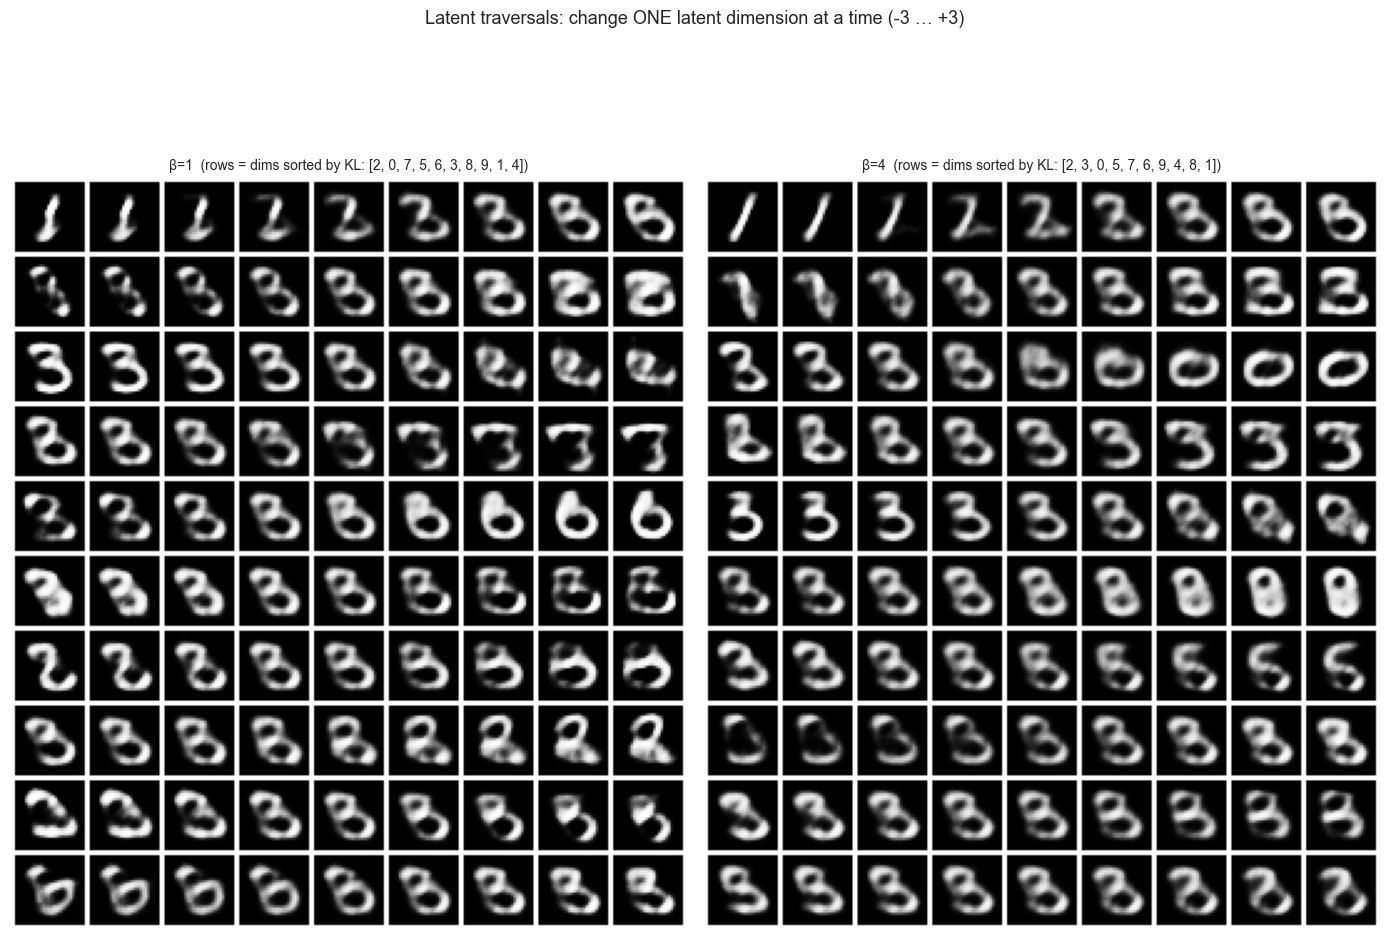

In [9]:
def traversal(m, b, x, n_dims=None, steps=9, rng=3.0, ax=None):
    """Rows = latent dimensions (sorted by KL), columns = value from -rng to +rng."""
    kl_dim, _, active, _ = stats[b]
    order = np.argsort(-kl_dim)[: n_dims or LATENT]
    with torch.no_grad():
        mu, _ = m.encode(x[None]); rows = []
        for d in order:
            z = mu.repeat(steps, 1); z[:, d] = torch.linspace(-rng, rng, steps, device=device)
            rows.append(m.decode(z))
    show_grid(torch.cat(rows), nrow=steps, ax=ax)
    ax.set_title(f"β={b}  (rows = dims sorted by KL: {list(order)})", fontsize=10)

x0 = Xte[(yte == 3).nonzero()[0, 0]]
fig, axes = plt.subplots(1, 2, figsize=(14, 11))
traversal(models[1], 1, x0, ax=axes[0])
traversal(models[4], 4, x0, ax=axes[1])
plt.suptitle("Latent traversals: change ONE latent dimension at a time (-3 … +3)", fontsize=13)
plt.tight_layout(); plt.show()

### Conclusion on disentanglement
**Verdict: the β-VAE with β = 4 gives the more disentangled representation.** The improvement is real but **moderate**:

* **Independence (quantitative):** the mean absolute correlation between latent dimensions falls from **0.080 (β=1) → 0.058 (β=2) → 0.043 (β=4)**. With β = 4 the 10 latent factors are almost twice as independent as in the standard VAE. This is the effect of the stronger pull towards the *factorised* prior $\mathcal{N}(0,I)$.
* **Information distribution:** with β = 1 all 10 dimensions carry a similar amount of information (1.5–2.1 nats each), so the information is **spread evenly** across all dimensions. With β = 4 the KL per dimension becomes **uneven** (0.4–1.4 nats): a few dimensions carry the main factors, and the others carry only small refinements. With β = 8 two dimensions (4 and 8) are **switched off completely** (KL ≈ 0) and a third is almost off.
* **Traversals (qualitative):** for the standard VAE, changing one dimension often changes **several properties at once**, for example digit identity together with thickness, slant and blob-like distortions (rows 2, 6 and 9 on the left). For β = 4 the rows change **more smoothly and more cleanly**: one row moves along a single digit transition (3 → 0, 8 → 3, 3 → 5), another mainly changes **stroke thickness and boldness**, and the low-KL rows hardly change the image at all.
* **Why not β = 8?** It switches off more dimensions, but its correlation rises again (0.068). The few remaining dimensions must squeeze all the information into very little capacity, so they get **re-entangled**, and the reconstructions become prototypical digits (BCE 145).
* **Honest limitation:** on MNIST the dominant factor of variation, the *digit class*, is **discrete**, and no single continuous dimension can represent it. That is why even the β-VAE traversals mostly morph one digit into another. Benchmarks like *dSprites* or *3D Shapes* have known continuous factors (x, y, scale, rotation) and allow formal metrics (β-VAE metric, MIG, DCI). Training for only 5 epochs also makes the trends less sharp than in a full run.
* **Trade-off:** the gain in disentanglement costs reconstruction quality (BCE 95.8 → 118.0 for β = 4). A **moderate β (about 2–4)** gives the best balance on MNIST.

---
## Task 6: Real-world applications of VAEs and limitations compared with GANs

### Applications
1. **Anomaly / fraud / defect detection:** a VAE trained only on normal data reconstructs normal samples well. A high reconstruction error or low ELBO flags anomalies (credit-card fraud, manufacturing defects, network intrusions, medical scans).
2. **Drug and molecule design:** VAEs on SMILES strings or molecular graphs (e.g. Gómez-Bombarelli et al. 2018) map molecules into a continuous latent space. Optimisation in that space proposes new molecules with desired properties.
3. **Data compression and representation learning:** the encoder gives compact, semantically meaningful features for downstream tasks. **Latent diffusion models such as Stable Diffusion use a VAE** to compress images into the latent space where diffusion operates.
4. **Recommendation systems:** Mult-VAE (Liang et al. 2018) models a user's click history as a distribution and recommends items.
5. **Data augmentation, imputation and denoising:** generate extra training samples for rare classes, fill in missing sensor values, and denoise images or speech.
6. **Controllable generation and disentanglement:** β-VAEs give interpretable controls (pose, lighting, style) used in graphics, robotics (world models) and fairness research.

### Limitations of VAEs compared with GANs
| Aspect | VAE | GAN |
|---|---|---|
| **Sample sharpness** | ✘ **Blurry**: the pixel-wise likelihood (BCE/MSE) averages over plausible outputs | ✔ Sharp, realistic, because the discriminator penalises unrealistic images |
| **Objective** | Optimises a *lower bound* (ELBO) and not the true likelihood, so the approximation gap remains | Adversarial objective, no explicit likelihood |
| **Posterior / prior mismatch** | The Gaussian posterior and isotropic prior are restrictive, and "holes" in the aggregate posterior produce poor samples | No explicit posterior assumption |
| **Posterior collapse** | A powerful decoder can ignore $z$ (KL → 0) | Not applicable |
| **Reconstruction–regularisation trade-off** | β trades sharpness against latent structure, as seen above | Not applicable |
| **Training stability** | ✔ Stable and easy to train, a single loss | ✘ Unstable (mode collapse, vanishing gradients, careful balancing needed) |
| **Encoder / likelihood** | ✔ Provides an encoder and an ELBO for density estimation | ✘ No encoder (unless BiGAN) and no likelihood |
| **Mode coverage** | ✔ Covers all modes (diverse samples) | ✘ May suffer mode collapse |

**In short:** VAEs are stable, principled and give a useful latent space and encoder, but their samples are less sharp than those of GANs. This motivates hybrids such as VAE-GAN, VQ-VAE and the VAE + diffusion combination used in latent diffusion.